# 01 - Audit Dataset & EDA
Dataset World Bank RTFP Indonesia. Semua angka dihitung dari file aktual.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

In [2]:
from src.data_loader import load_raw
raw = load_raw()
print(raw.shape)
raw.dtypes.value_counts()

(53297, 74)


float64    60
str        11
int64       3
Name: count, dtype: int64

In [3]:
info = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_%': (raw.isna().mean()*100).round(2), 'unik': raw.nunique()})
info

,dtype,missing,missing_%,unik
ISO3,str,0,0.00,1
country,str,0,0.00,1
adm1_name,str,0,0.00,35
adm2_name,str,0,0.00,112
mkt_name,str,0,0.00,223
...,...,...,...,...
h_food_price_index,float64,0,0.00,132
l_food_price_index,float64,0,0.00,130
c_food_price_index,float64,0,0.00,133
inflation_food_price_index,float64,2676,5.02,4227


In [4]:
print('Duplikasi baris:', raw.duplicated().sum(), '| duplikasi (pasar, bulan):', raw.duplicated(['geo_id','price_date']).sum())
print('Pasar:', raw.geo_id.nunique(), '| Provinsi:', raw.adm1_name.nunique(), '| Kab/Kota:', raw.adm2_name.nunique())
print('Periode:', raw.price_date.min(), '-', raw.price_date.max(), '| spatially_interpolated:', raw.spatially_interpolated.unique(), '| last_survey_point:', raw.last_survey_point.unique())

Duplikasi baris: 0 | duplikasi (pasar, bulan): 0
Pasar: 223 | Provinsi: 35 | Kab/Kota: 112
Periode: 2007-01-01 - 2026-11-01 | spatially_interpolated: [0] | last_survey_point: <ArrowStringArray>
['Sep 2026']
Length: 1, dtype: str


**Temuan kunci:** kolom tanpa prefiks (mis. `rice`) = harga observasi; `c_*` = *close estimate* (estimasi model World Bank, terisi penuh). Hanya ~32% sel merupakan observasi, dan observasi padat baru ada sejak 2020. Baris `gid_idn_national_average` adalah agregat nasional (bukan pasar) dan dikeluarkan. Oktober-November 2026 tidak memiliki observasi (last survey point = Sep 2026).

In [5]:
from src.preprocessing import build_long
long = build_long(raw)
long.groupby('year')['is_observed'].mean().round(3)

Baris agregat rata-rata nasional dikeluarkan: 239
Duplikasi (geo_id, tanggal) dihapus: 0


Baris long: 371,406 | observasi: 119,021 | outlier ditandai: 30 | hanya estimasi: 252,385


year
2007    0.000
2008    0.000
2009    0.000
2010    0.000
2011    0.000
2012    0.000
2013    0.000
2014    0.000
2015    0.000
2016    0.322
2017    0.060
2018    0.000
2019    0.000
2020    0.898
2021    0.937
2022    0.940
2023    0.926
2024    0.706
2025    0.943
2026    0.711
Name: is_observed, dtype: float64

In [6]:
from src.eda import make_eda_figures
s = make_eda_figures(raw, long)
pd.DataFrame(s['per_commodity']).T.round(1)

,n_observed,observed_share,obs_min,obs_max,obs_mean,obs_median,est_min,est_max,est_mean,est_median
eggs,16991.0,0.3,12500.0,80000.0,27488.0,27200.0,6946.0,45000.0,20753.0,20102.2
garlic,17083.0,0.3,12850.0,90000.0,34903.1,35000.0,9566.8,66288.2,32549.6,31372.0
meat_chicken,16780.0,0.3,14000.0,72000.0,35228.3,35000.0,15550.6,60000.0,30334.8,29473.2
oil,16998.0,0.3,10840.0,42500.0,18624.7,18562.1,6155.0,32020.1,13635.1,12743.8
onions,17158.0,0.3,11428.6,100476.2,37912.1,36285.7,15217.2,80000.0,34035.9,33844.0
rice,16804.0,0.3,7150.0,26650.0,13216.0,13123.9,5658.8,21623.3,10612.9,10298.1
sugar,17177.0,0.3,9829.0,32000.0,15683.2,15000.0,8269.2,22000.0,13415.1,13500.0


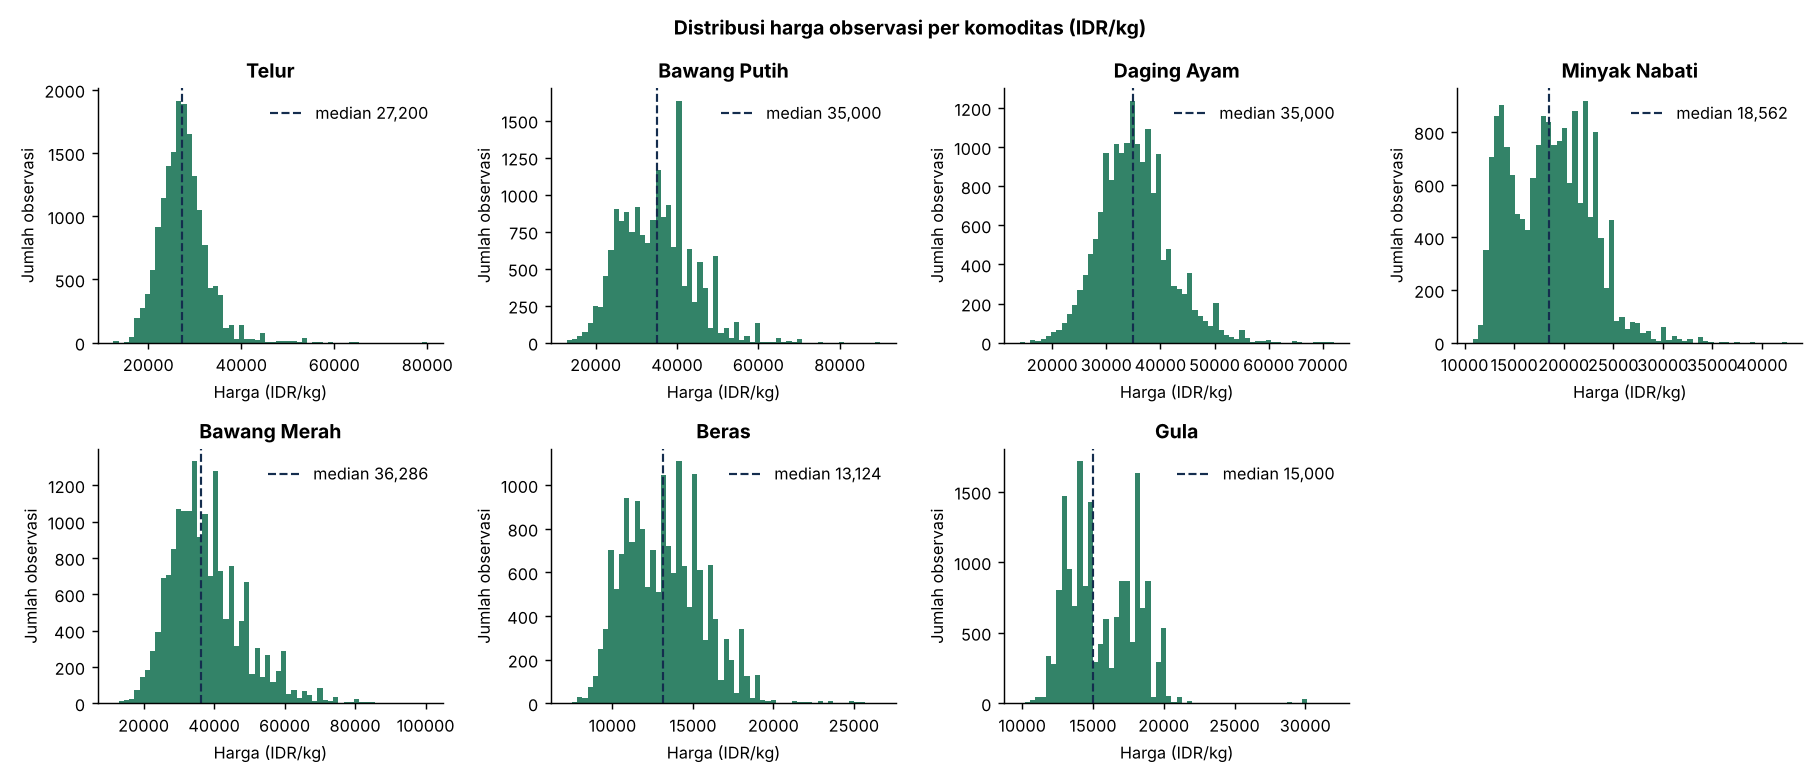

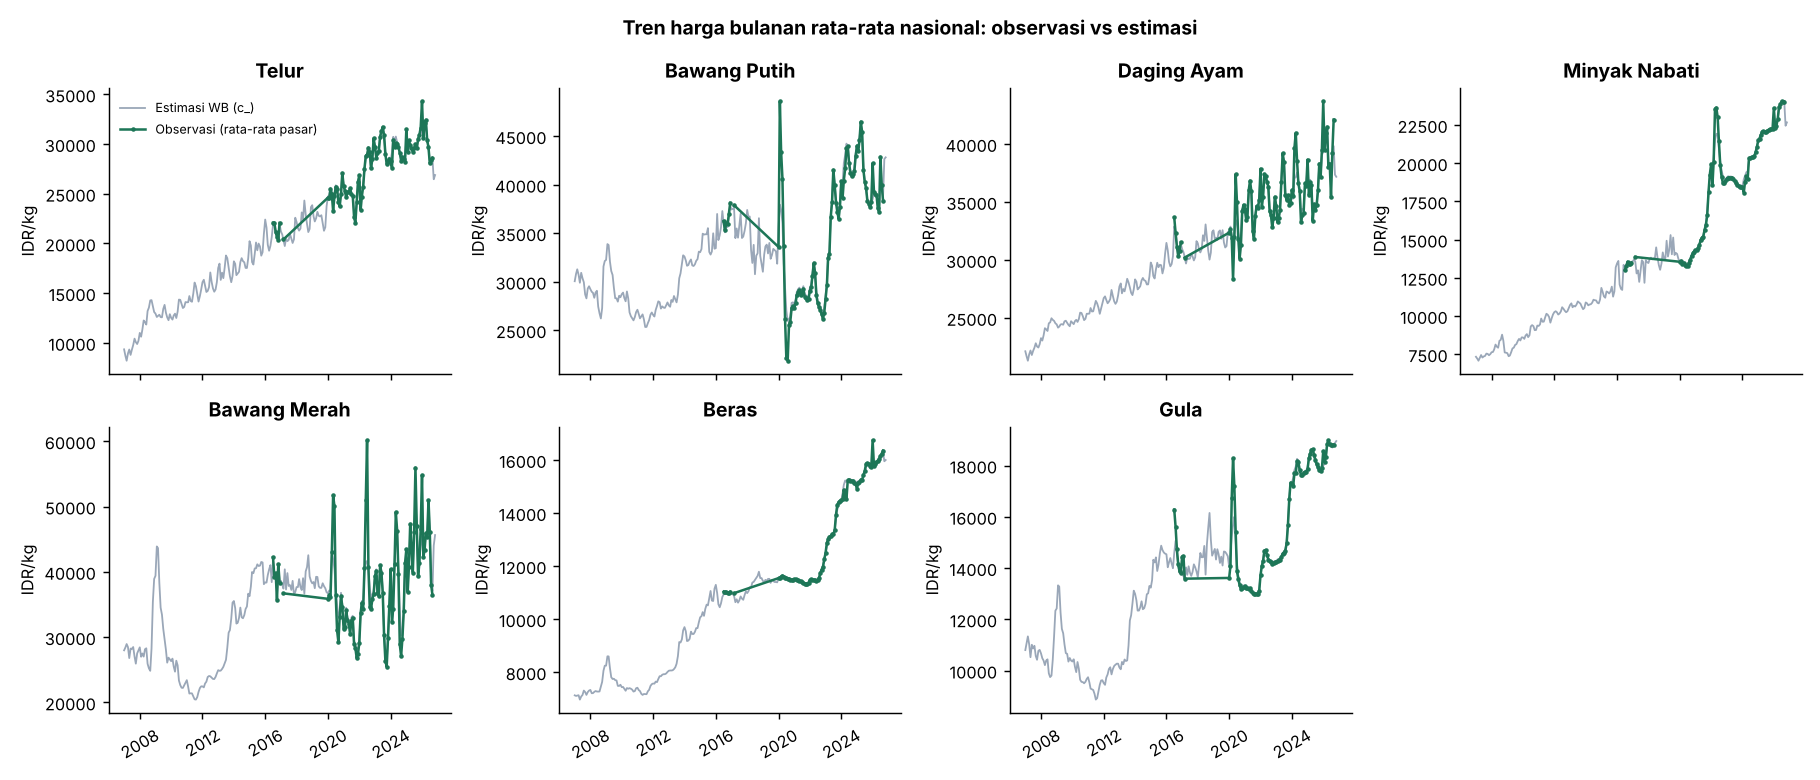

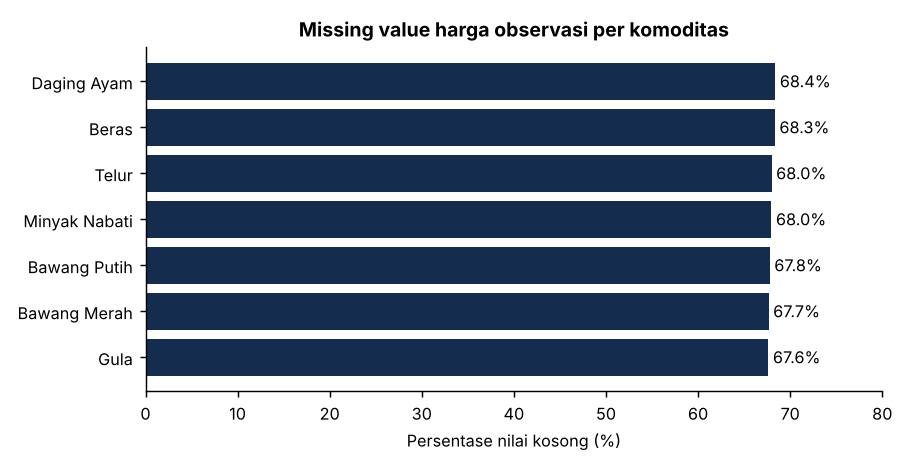

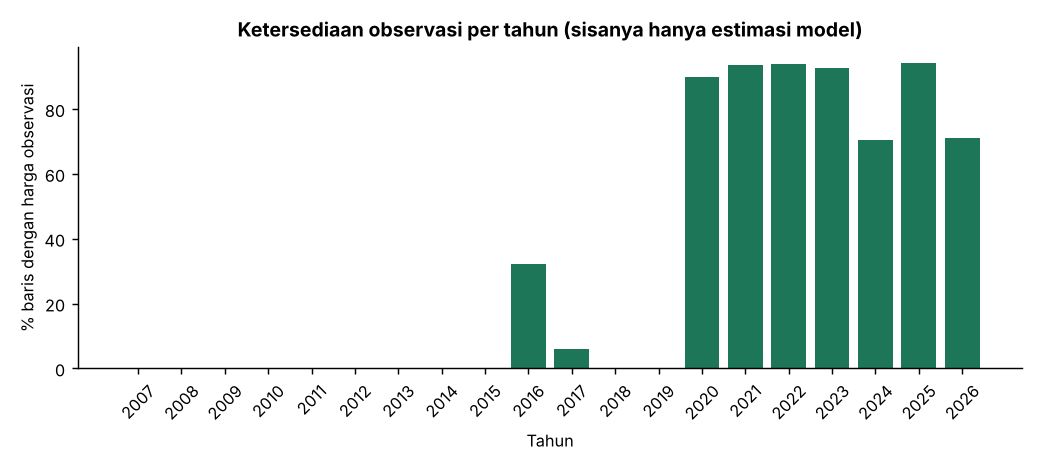

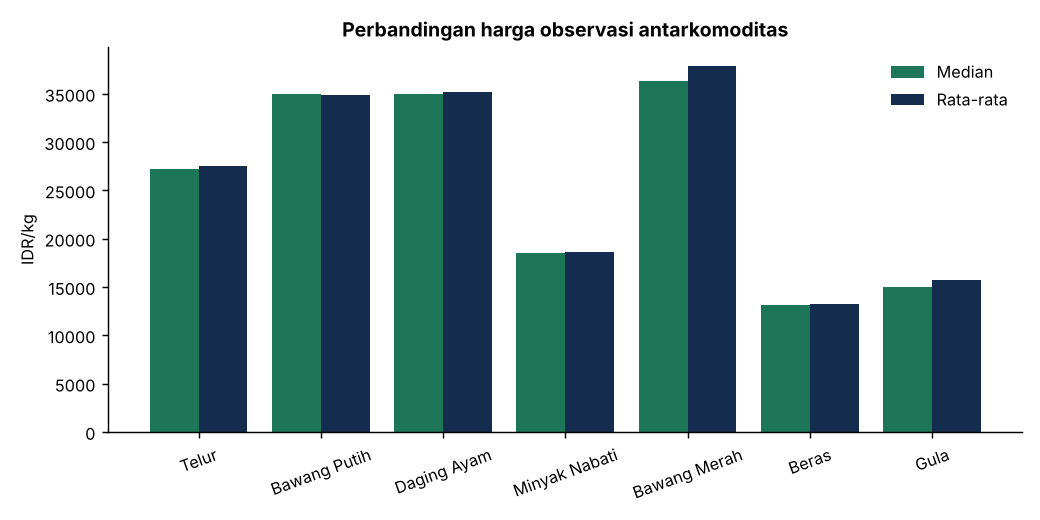

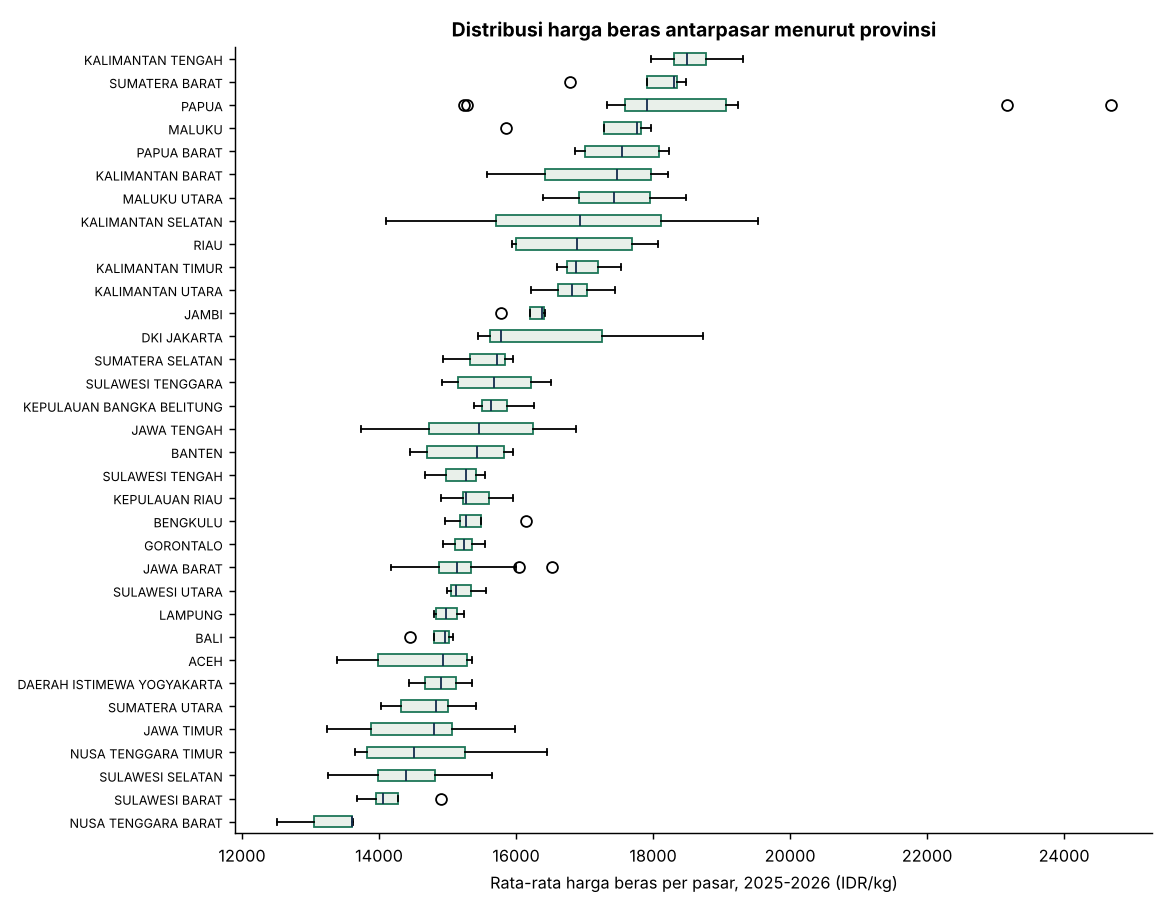

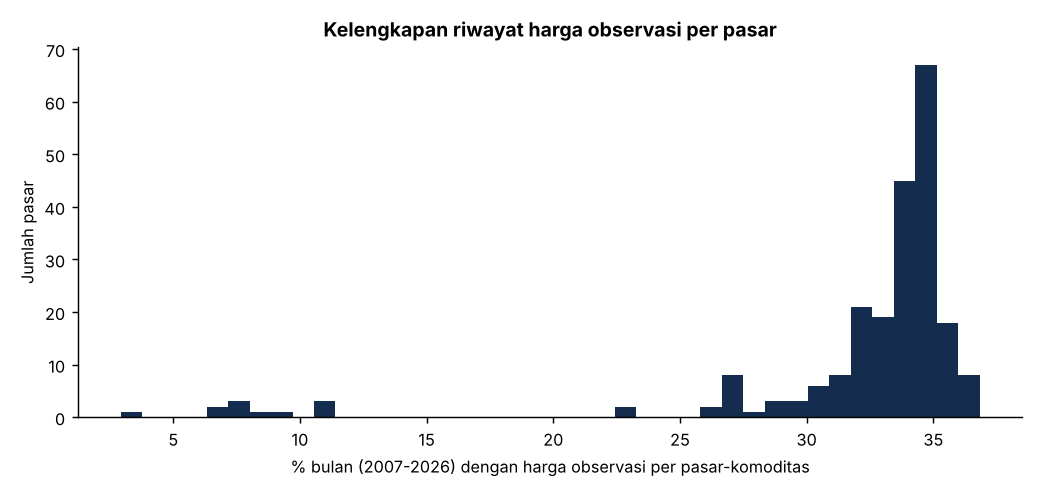

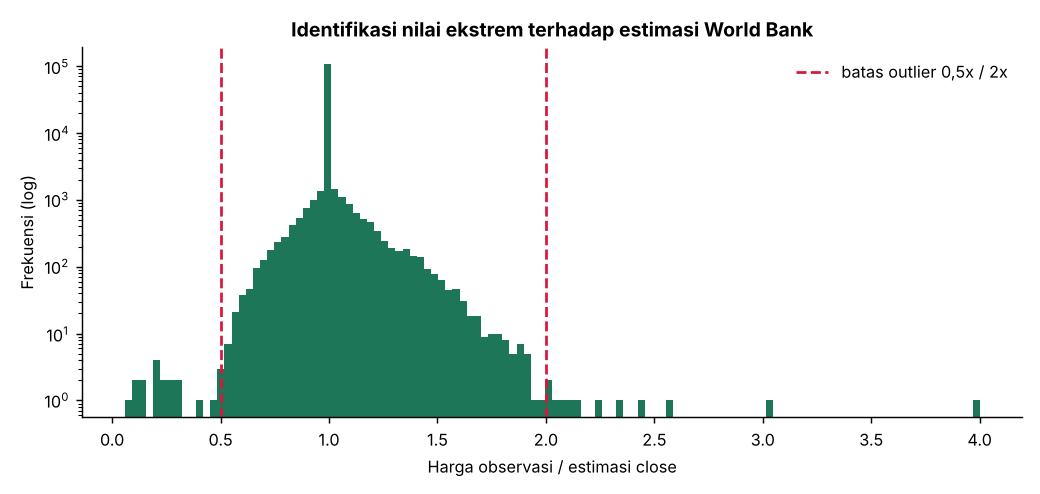

In [7]:
for f in sorted(Path('results/figures').glob('eda_*.png')):
    display(Image(str(f)))

## Kesimpulan EDA
1. 53.297 baris x 74 kolom, 223 `geo_id` = 222 pasar + 1 baris agregat 'Market Average' (rata-rata nasional, dikeluarkan dari analisis pasar), 35 provinsi, 239 bulan (Jan 2007-Nov 2026), tanpa duplikasi.
2. Panel seimbang, tetapi hanya ~32% sel berisi harga observasi; sisanya estimasi model.
3. Observasi pasar ada sejak 2016 (2017 nyaris kosong, 2018-2019 tidak ada); padat Jan 2020-Sep 2026 (celah: Feb-Mei 2024 dan Jan 2026).
4. 30 observasi ekstrem (rasio terhadap estimasi di luar 0,5x-2x) ditandai outlier dan dikecualikan dari pemodelan (tidak dihapus dari dataset).
5. `spatially_interpolated` bernilai 0 untuk seluruh baris.